# Methods comparison: every stage of the pipeline, several ways
`model_comparison.ipynb` compared models. This notebook keeps the model fixed (Heston, live SPX snapshot of 30 September 2026, v1 expiry rule: 1M, 3M, 6M and the semi-annual product dates) and compares **methods** at each stage, always on the same data and against a reference:

| Stage | Current choice | Alternatives compared |
|---|---|---|
| 1. Vanilla pricing engine | Lewis integral, FFT + cubic spline | Lewis with Gauss-Legendre quadrature; COS method; Carr-Madan damped FFT; Heston's original two-integral form; adaptive quadrature as reference |
| 2. Implied-vol inversion | vectorised bisection | safeguarded Newton; Brent per option |
| 3. Calibration objective | spread-weighted vol RMSE | price RMSE (v1); relative price; vega-weighted price; uniform vol RMSE; Huber vol loss |
| 4. Optimiser | differential evolution + L-BFGS-B | DE variants (strategy, population); dual annealing; basin hopping; SHGO; Nelder-Mead; multistart L-BFGS-B; Levenberg-Marquardt-type `least_squares` |
| 5. Expiry selection | nearest listed expiry to each target | most liquid listed expiry within a window |
| 6. Monte Carlo | QE, pseudo-random, daily steps | Euler; antithetic; control variates (digitals and the knock-in put); scrambled Sobol with and without a Brownian bridge |
| 7. Vol surface for LV/LSV | (none) | SSVI vs slice-by-slice SVI, both arbitrage-checked; Dupire local vol |
| 8. Dynamics for the note | Heston | local vol (Dupire); local-stochastic vol (Heston with a particle-calibrated leverage function) |

Each section states the method, the reference it is checked against, and reports accuracy and time.


In [1]:
import numpy as np, pandas as pd, time
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import heston_pricer as hp
from heston_pricer import (rate_curve_func, set_rate_curve, OISBootstrapper, attach_quote_details, filter_call_spread_arbitrage,
                           implied_vol_call_vec, bs_vega, HestonAutocallPricer, heston_engine_qe_numba, heston_engine_euler_numba)
from vol_models import HestonModel, FFTCalibrator
from methods import *
pd.set_option('display.width', 220)

DATA_FILE = "calibration_data_September_30_2026.xlsx"
_spot = pd.read_excel(DATA_FILE, sheet_name="Spot Price"); S0 = float(_spot['S0'].iloc[0])
PRICING_DATE = pd.to_datetime(_spot['Date'].iloc[0]).to_pydatetime().replace(hour=0, minute=0, second=0, microsecond=0)
try:
    _rates = pd.read_excel(DATA_FILE, sheet_name="Rates"); set_rate_curve(list(zip(_rates['tenor_years'], _rates['rate_pct'])), coupon_freq=2)
    RATE_SOURCE = f"{_rates['source'].iloc[0]}, as of {_rates['as_of'].iloc[-1]}"
except ValueError:
    set_rate_curve(OISBootstrapper.DEFAULT_MARKET_DATA, coupon_freq=1); RATE_SOURCE = "Bloomberg SOFR OIS, 3 Dec 2025"
clean = pd.read_excel(DATA_FILE, sheet_name="Cleaned Data")
sched = [PRICING_DATE + 2 * timedelta(days=183)]
for _ in range(6): sched.append(sched[-1] + timedelta(days=183))
PRODUCT_SCHEDULE = [d.strftime("%Y-%m-%d") for d in sched]
OBS_TIMES = HestonAutocallPricer.schedule_to_times(PRODUCT_SCHEDULE, PRICING_DATE); T_MAX = OBS_TIMES[-1]
PRODUCT_PARAMS = {"full_schedule": PRODUCT_SCHEDULE, "coupon_step": 0.03, "barrier_redemption": 0.70, "barrier_knock_in": 0.60,
                  "exit_bonus": 0.24, "nominal": 1000, "payment_lag_days": 7}
targets = sorted(set([0.08, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0] + list(OBS_TIMES)))
available = np.sort(clean['T'].unique()); selected = []
for t in targets:
    c = available[np.abs(available - t).argmin()]
    if c not in selected: selected.append(c)
df_sel = clean[clean['T'].isin(selected)].reset_index(drop=True)
q_data = df_sel[['T', 'implied_q']].groupby('T').mean().sort_index()
dividend_curve_func = lambda T: np.interp(T, q_data.index.values, q_data['implied_q'].values)
df_sel = attach_quote_details(df_sel, DATA_FILE, rate_curve_func)
df_all, df_dropped = filter_call_spread_arbitrage(df_sel, rate_curve_func)
SHORT_T = 0.4
cal = FFTCalibrator(df_all, S0, rate_curve_func, model=HestonModel(), objective='iv')
print(f"Snapshot {PRICING_DATE.date()}, spot {S0:.2f}; {RATE_SOURCE}")
print(f"Expiries {np.round(selected, 3)}; quotes {len(df_all)} after the call-spread filter ({len(df_dropped)} removed)")

# Reference Heston parameters: the 6M+ fit used in main.ipynb (recomputed here so the notebook is self-contained)
cal_6m = FFTCalibrator(df_all[df_all['T'] >= SHORT_T], S0, rate_curve_func, model=HestonModel(), objective='iv')
PARAMS = cal_6m.calibrate(verbose=False, seed=42).x
print("Heston (6M+ fit):", dict(zip(HestonModel.param_names, np.round(PARAMS, 4))))


Snapshot 2026-09-30, spot 7696.50; FRED Treasury constant-maturity yield (proxy for SOFR OIS), as of 2026-09-28
Expiries [0.088 0.249 0.496 0.997 1.307 2.208 3.225 4.222]; quotes 1273 after the call-spread filter (87 removed)


Heston (6M+ fit): {'kappa': np.float64(2.8733), 'theta': np.float64(0.0527), 'sigma': np.float64(1.5257), 'rho': np.float64(-0.6096), 'v0': np.float64(0.0247)}


## 1. Vanilla pricing engines
All engines price the same Heston model on the same 1,273 quotes. Reference: adaptive quadrature (QUADPACK) of the Lewis integral, strike by strike, to 1e-10. Errors in index points and, more usefully, in implied-vol points; time per full surface (8 expiries), which is what one calibration objective evaluation costs.


In [2]:
model = HestonModel()
engines = {
    'Lewis FFT + cubic spline (N=4096, B=300)  [current]': lambda b, K: cal.price_calls(PARAMS, b['T'], K, b['q']),
    'Lewis, Gauss-Legendre 1500 nodes on [0, 300]': lambda b, K: price_lewis_gauss_legendre(model, PARAMS, S0, K, b['T'], cal.r_curve(b['T']), b['q']),
    'COS, N=256 terms, L=10': lambda b, K: price_cos(model, PARAMS, S0, K, b['T'], cal.r_curve(b['T']), b['q'], N=256),
    'COS, N=512 terms, L=10': lambda b, K: price_cos(model, PARAMS, S0, K, b['T'], cal.r_curve(b['T']), b['q'], N=512),
    'Carr-Madan FFT, alpha=1.5 (N=4096, eta=0.25)': lambda b, K: price_carr_madan_fft(model, PARAMS, S0, K, b['T'], cal.r_curve(b['T']), b['q'], alpha=1.5),
    'Carr-Madan FFT, alpha=0.75': lambda b, K: price_carr_madan_fft(model, PARAMS, S0, K, b['T'], cal.r_curve(b['T']), b['q'], alpha=0.75),
    'Heston 1993 two integrals, Gauss-Legendre 4000 on [0, 200]': lambda b, K: price_heston_two_integral(model, PARAMS, S0, K, b['T'], cal.r_curve(b['T']), b['q']),
}
t0 = time.perf_counter()
refs = {b['T']: price_lewis_reference(model, PARAMS, S0, b['strikes'], b['T'], cal.r_curve(b['T']), b['q']) for b in cal.data_batches}
print(f"reference: {time.perf_counter() - t0:.1f} s for {len(cal.flat_K)} quotes")
rows = []
for name, fn in engines.items():
    t0 = time.perf_counter()
    for _ in range(3): out = [fn(b, b['strikes']) for b in cal.data_batches]
    secs = (time.perf_counter() - t0) / 3
    errs, iv_errs, worst_T = [], [], None
    for b, p in zip(cal.data_batches, out):
        ref = refs[b['T']]; rT = cal.r_curve(b['T'])
        errs.append(np.abs(p - ref))
        iv_errs.append(np.abs(implied_vol_call_vec(p, S0, b['strikes'], b['T'], rT, b['q']) - implied_vol_call_vec(ref, S0, b['strikes'], b['T'], rT, b['q'])))
    e = np.concatenate(errs); ie = np.concatenate(iv_errs)
    rows.append({'engine': name, 'max |err| (pts)': e.max(), 'mean |err| (pts)': e.mean(), 'max IV err (vol pts)': 100 * ie.max(),
                 'RMS IV err (vol pts)': 100 * np.sqrt(np.mean(ie**2)), 'ms / surface': 1000 * secs, 'worst expiry': f"{cal.data_batches[int(np.argmax([x.max() for x in errs]))]['T']:.2f}y"})
engines_table = pd.DataFrame(rows).set_index('engine')
display(engines_table.round(4))


reference: 16.7 s for 1273 quotes


,max |err| (pts),mean |err| (pts),max IV err (vol pts),RMS IV err (vol pts),ms / surface,worst expiry
engine,,,,,,
"Lewis FFT + cubic spline (N=4096, B=300) [current]",0.4193,0.0085,0.0468,0.0036,9.0194,0.09y
"Lewis, Gauss-Legendre 1500 nodes on [0, 300]",0.0028,0.0000,0.0094,0.0003,195.7417,0.09y
"COS, N=256 terms, L=10",0.0191,0.0023,0.0010,0.0002,14.9361,1.31y
"COS, N=512 terms, L=10",0.0191,0.0023,0.0010,0.0002,16.7824,1.31y
"Carr-Madan FFT, alpha=1.5 (N=4096, eta=0.25)",0.0033,0.0000,0.0029,0.0001,10.8577,0.09y
"Carr-Madan FFT, alpha=0.75",0.2076,0.2061,46.3655,1.7495,11.2178,0.09y
"Heston 1993 two integrals, Gauss-Legendre 4000 on [0, 200]",0.2681,0.0122,46.3655,1.7406,3233.8488,0.09y


## 2. Implied-vol inversion
Every vol-space objective evaluation inverts 1,273 model prices. Reference: Brent's method per option to 1e-12.


In [3]:
C = cal.flat_market; K = cal.flat_K; T = cal.flat_T; r = cal.flat_r; q = cal.flat_q
t0 = time.perf_counter(); ref_iv = implied_vol_brent_loop(C, S0, K, T, r, q); t_brent = time.perf_counter() - t0
rows = [{'solver': 'Brent per option (scipy brentq)  [reference]', 'max |err| (vol pts)': 0.0, 'ms for 1273 options': 1000 * t_brent}]
for name, fn in [('bisection, 50 iterations  [current]', lambda: implied_vol_call_vec(C, S0, K, T, r, q, n_iter=50)),
                 ('bisection, 30 iterations', lambda: implied_vol_call_vec(C, S0, K, T, r, q, n_iter=30)),
                 ('safeguarded Newton, 25 iterations', lambda: implied_vol_newton(C, S0, K, T, r, q, n_iter=25)),
                 ('safeguarded Newton, 10 iterations', lambda: implied_vol_newton(C, S0, K, T, r, q, n_iter=10))]:
    t0 = time.perf_counter(); [fn() for _ in range(5)]; secs = (time.perf_counter() - t0) / 5
    rows.append({'solver': name, 'max |err| (vol pts)': 100 * np.max(np.abs(fn() - ref_iv)), 'ms for 1273 options': 1000 * secs})
display(pd.DataFrame(rows).set_index('solver').round(6))


,max |err| (vol pts),ms for 1273 options
solver,,
Brent per option (scipy brentq) [reference],0.000000,1270.921708
"bisection, 50 iterations [current]",0.000000,7.357492
"bisection, 30 iterations",0.000000,4.331717
"safeguarded Newton, 25 iterations",0.000461,6.186658
"safeguarded Newton, 10 iterations",15.114142,2.440458


## 3. Calibration objectives
Same optimiser (DE, seed 42, then L-BFGS-B), same quotes, six objectives. Every fit is then scored with the same yardsticks: unweighted vol RMSE overall, on the short end and on 6M+, price RMSE, the largest vol miss, and the mean vol error at the product strikes.


In [4]:
def product_strike_error(c, params):
    errs = []
    for b in c.data_batches:
        if b['T'] < 0.9: continue
        rT = c.r_curve(b['T'])
        for mon in [0.6, 0.7, 0.8, 0.9, 1.0]:
            j = np.argmin(np.abs(b['strikes'] - mon * S0)); Kj = b['strikes'][j]
            errs.append(100 * abs(implied_vol_call_vec(c.price_calls(params, b['T'], [Kj], b['q']), S0, Kj, b['T'], rT, b['q'])[0] - c.market_iv[c.flat_T == b['T']][j]))
    return float(np.mean(errs))

objective_names = {'price': 'price RMSE  [v1]', 'relprice': 'relative price RMSE', 'vega': 'vega-weighted price RMSE',
                   'iv_uniform': 'vol RMSE, uniform weights', 'iv_spread': 'vol RMSE, 1/spread^2 weights  [current]', 'iv_huber': 'Huber vol loss (delta = 1 vol pt)'}
obj_rows = []; obj_fits = {}
for mode, label in objective_names.items():
    c = ObjectiveCalibrator(df_all, S0, rate_curve_func, mode=mode)
    t0 = time.perf_counter(); res = c.calibrate(verbose=False, seed=42); secs = time.perf_counter() - t0
    sp = cal.error_split(res.x, SHORT_T); obj_fits[mode] = res.x
    obj_rows.append({'objective': label, 'vol RMSE all': sp['all']['IV RMSE'], 'vol RMSE 1M-3M': sp['short (<6M)']['IV RMSE'], 'vol RMSE 6M+': sp['6M+']['IV RMSE'],
                     'price RMSE all': sp['all']['price RMSE'], 'price RMSE 6M+': sp['6M+']['price RMSE'], 'max |vol err|': sp['all']['max |IV err|'],
                     'product strikes': product_strike_error(cal, res.x), 'seconds': secs, 'sigma': res.x[2], 'rho': res.x[3]})
objectives_table = pd.DataFrame(obj_rows).set_index('objective')
display(objectives_table.round(3))


,vol RMSE all,vol RMSE 1M-3M,vol RMSE 6M+,price RMSE all,price RMSE 6M+,max |vol err|,product strikes,seconds,sigma,rho
objective,,,,,,,,,,
price RMSE [v1],1.606,2.180,0.845,10.011,12.906,18.613,0.217,40.269,1.072,-0.623
relative price RMSE,1.990,1.768,2.164,26.890,36.384,13.195,2.662,42.103,1.699,-0.671
vega-weighted price RMSE,0.989,1.300,0.607,12.175,14.966,12.247,0.174,38.017,1.698,-0.624
"vol RMSE, uniform weights",0.941,1.180,0.672,13.068,15.408,6.438,0.224,63.260,2.537,-0.572
"vol RMSE, 1/spread^2 weights [current]",0.899,1.146,0.613,12.245,14.880,9.444,0.197,64.805,2.069,-0.587
Huber vol loss (delta = 1 vol pt),1.018,1.343,0.615,11.748,14.845,12.778,0.148,65.494,1.661,-0.591


## 4. Optimisers
All on the current objective (spread-weighted vol RMSE, 5 Heston parameters, all 8 expiries). Stochastic methods run with two seeds; the table shows the best and worst objective reached, the evaluations and the wall time. `least_squares` is the Levenberg-Marquardt / trust-region family that uses the residual vector (one residual per quote) rather than the scalar objective, which is what most production calibrators do.


In [5]:
cal_opt = ObjectiveCalibrator(df_all, S0, rate_curve_func, mode='iv_spread')
opt_methods = [('de_lbfgs', 'DE best1bin (pop 15/param, 50 gen) + L-BFGS-B  [current]', [42, 7]), ('de', 'DE best1bin, no local step', [42, 7]),
               ('de_rand1', 'DE rand1bin + L-BFGS-B', [42, 7]), ('de_c2b', 'DE currenttobest1bin', [42, 7]), ('de_small_pop', 'DE small population (5/param, 150 gen)', [42, 7]),
               ('dual_annealing', 'dual annealing (maxiter 60) + local', [42, 7]), ('basinhopping', 'basin hopping from heuristic start (12 hops)', [42, 7]),
               ('shgo', 'SHGO (sobol, n=32)', [42]), ('nelder_mead', 'Nelder-Mead from heuristic start', [42]),
               ('lbfgs_multistart', 'L-BFGS-B, 12 Latin-hypercube starts', [42, 7]), ('least_squares', 'least_squares (trf) from heuristic start', [42]),
               ('least_squares_multistart', 'least_squares, heuristic + 5 LHS starts', [42, 7])]
opt_rows = []; best_overall = None
for m, label, seeds in opt_methods:
    runs = [run_optimizer(cal_opt, m, seed=s) for s in seeds]
    funs = [100 * r_['fun'] for r_ in runs]
    best = min(runs, key=lambda r_: r_['fun'])
    if best_overall is None or best['fun'] < best_overall['fun']: best_overall = best
    opt_rows.append({'optimiser': label, 'best objective (vol pts)': min(funs), 'worst objective (vol pts)': max(funs), 'evaluations (mean)': np.mean([r_['nfev'] for r_ in runs]),
                     'seconds (mean)': np.mean([r_['seconds'] for r_ in runs]), 'kappa': best['x'][0], 'sigma': best['x'][2], 'rho': best['x'][3]})
    print(f"{label:55s} best {min(funs):.4f}  worst {max(funs):.4f}  {np.mean([r_['seconds'] for r_ in runs]):6.1f} s")
optimisers_table = pd.DataFrame(opt_rows).set_index('optimiser')
display(optimisers_table.round(4))
print(f"Best objective found by any method: {100 * best_overall['fun']:.4f} vol pts ({best_overall['method']}), params {np.round(best_overall['x'], 4)}")


DE best1bin (pop 15/param, 50 gen) + L-BFGS-B  [current] best 0.7729  worst 0.7729    65.1 s


DE best1bin, no local step                              best 0.7729  worst 0.7731    63.3 s


DE rand1bin + L-BFGS-B                                  best 0.8553  worst 0.8874    63.2 s


DE currenttobest1bin                                    best 0.7767  worst 0.7851    64.2 s


DE small population (5/param, 150 gen)                  best 0.7729  worst 0.7729    28.1 s


...

L-BFGS-B, 12 Latin-hypercube starts                     best 0.7729  worst 0.7729   101.3 s


least_squares (trf) from heuristic start                best 0.7729  worst 0.7729     0.9 s


least_squares, heuristic + 5 LHS starts                 best 0.7729  worst 0.7729     9.1 s


,best objective (vol pts),worst objective (vol pts),evaluations (mean),seconds (mean),kappa,sigma,rho
optimiser,,,,,,,
"DE best1bin (pop 15/param, 50 gen) + L-BFGS-B [current]",0.7729,0.7729,3888.0,65.0888,4.2489,2.0692,-0.5868
"DE best1bin, no local step",0.7729,0.7731,3825.0,63.2851,4.2289,2.0721,-0.5854
DE rand1bin + L-BFGS-B,0.8553,0.8874,3825.0,63.1604,4.5521,2.1399,-0.6369
DE currenttobest1bin,0.7767,0.7851,3825.0,64.1695,4.3933,2.1315,-0.5721
"DE small population (5/param, 150 gen)",0.7729,0.7729,1712.5,28.0690,4.2595,2.0751,-0.5862
dual annealing (maxiter 60) + local,0.9163,1.0258,901.0,15.9836,5.5213,2.0986,-0.7106
basin hopping from heuristic start (12 hops),0.7729,0.7729,3138.0,62.6857,4.2483,2.0720,-0.5863
"SHGO (sobol, n=32)",0.7729,0.7729,903.0,18.1105,4.2489,2.0722,-0.5863
Nelder-Mead from heuristic start,0.7729,0.7729,575.0,9.6959,4.2479,2.0719,-0.5863


Best objective found by any method: 0.7729 vol pts (nelder_mead), params [ 4.2479  0.0514  2.0719 -0.5863  0.0199]


### 4b. The harder case: double Heston (10 parameters)
In `model_comparison.ipynb` differential evolution gave different answers for double Heston depending on the seed. Here the residual-based `least_squares` is started from eight Latin-hypercube points and compared with DE on the same objective. `nfev` for `least_squares` counts function evaluations only; each iteration also needs a finite-difference Jacobian (10 more evaluations), so the true cost is roughly 11x the number shown.


In [6]:
from vol_models import DoubleHestonModel
from scipy import optimize, stats
class DHCal(FFTCalibrator):
    def residual_vector(self, params):
        try:
            pv = self.price_surface(params)
            if not np.all(np.isfinite(pv)): raise ValueError
            iv = implied_vol_call_vec(pv, self.S0, self.flat_K, self.flat_T, self.flat_r, self.flat_q)
            return np.sqrt(self.quote_weights) * (iv - self.market_iv)
        except Exception:
            return np.full(len(self.flat_K), 1.0)
dh = DHCal(df_all, S0, rate_curve_func, model=DoubleHestonModel(), objective='iv')
lo = np.array([b[0] for b in dh.bounds]); hi = np.array([b[1] for b in dh.bounds])
dh_rows = []
for sd in [42, 7]:
    t0 = time.perf_counter(); res = dh.calibrate(verbose=False, maxiter=60, seed=sd)
    dh_rows.append({'method': f'DE (seed {sd}) + L-BFGS-B', 'objective (vol pts)': 100 * res.fun, 'seconds': time.perf_counter() - t0, 'sigma1': res.x[2], 'kappa2': res.x[5]})
t0 = time.perf_counter(); best = None; nfev = 0
starts = lo + stats.qmc.LatinHypercube(d=10, seed=42).random(8) * (hi - lo)
for s_ in starts:
    r_ = optimize.least_squares(dh.residual_vector, np.clip(s_, lo + 1e-6, hi - 1e-6), bounds=(lo, hi), method='trf', xtol=1e-10, ftol=1e-10, max_nfev=300)
    nfev += r_.nfev; val = dh.objective_function(r_.x)
    if best is None or val < best[1]: best = (r_.x, val)
dh_rows.append({'method': 'least_squares, 8 Latin-hypercube starts', 'objective (vol pts)': 100 * best[1], 'seconds': time.perf_counter() - t0, 'sigma1': best[0][2], 'kappa2': best[0][5]})
t0 = time.perf_counter(); r_ = optimize.least_squares(dh.residual_vector, dh_rows[1]['sigma1'] * 0 + res.x, bounds=(lo, hi), method='trf', xtol=1e-12, ftol=1e-12, max_nfev=300)
dh_rows.append({'method': 'least_squares polish of the DE seed-7 result', 'objective (vol pts)': 100 * dh.objective_function(r_.x), 'seconds': time.perf_counter() - t0, 'sigma1': r_.x[2], 'kappa2': r_.x[5]})
display(pd.DataFrame(dh_rows).set_index('method').round(4))


,objective (vol pts),seconds,sigma1,kappa2
method,,,,
DE (seed 42) + L-BFGS-B,0.4079,229.6351,3.3385,8.8618
DE (seed 7) + L-BFGS-B,0.3635,246.0146,3.6890,2.3305
"least_squares, 8 Latin-hypercube starts",0.3620,101.7689,0.3888,5.1179
least_squares polish of the DE seed-7 result,0.3620,5.2502,3.8256,1.8029


## 5. Expiry selection
The v1 rule maps each target tenor to the nearest listed expiry. The alternative maps it to the most liquid listed expiry (most quotes after the filter) within ±15% of the target. Heston fitted to 6M+ in both cases, scored on the product strikes.


In [7]:
def select_expiries(rule):
    out = []
    counts = clean.groupby('T').size()
    for t in targets:
        if rule == 'nearest':
            c = available[np.abs(available - t).argmin()]
        else:
            window = available[np.abs(available - t) <= 0.15 * max(t, 0.5)]
            c = (counts.loc[window].idxmax() if len(window) else available[np.abs(available - t).argmin()])
        if c not in out: out.append(c)
    return sorted(out)

sel_rows = []
for rule in ['nearest', 'most liquid in window']:
    exps = select_expiries(rule)
    d = clean[clean['T'].isin(exps)].reset_index(drop=True)
    d = attach_quote_details(d, DATA_FILE, rate_curve_func); d, _ = filter_call_spread_arbitrage(d, rate_curve_func)
    c_fit = FFTCalibrator(d[d['T'] >= SHORT_T], S0, rate_curve_func, model=HestonModel(), objective='iv')
    c_all = FFTCalibrator(d, S0, rate_curve_func, model=HestonModel(), objective='iv')
    res = c_fit.calibrate(verbose=False, seed=42); sp = c_all.error_split(res.x, SHORT_T)
    sel_rows.append({'rule': rule, 'expiries (y)': np.round(exps, 2).tolist(), 'quotes': len(d), 'vol RMSE 6M+': sp['6M+']['IV RMSE'],
                     'product strikes': product_strike_error(c_all, res.x), 'sigma': res.x[2], 'rho': res.x[3], 'v0': res.x[4]})
display(pd.DataFrame(sel_rows).set_index('rule').round(3))


,expiries (y),quotes,vol RMSE 6M+,product strikes,sigma,rho,v0
rule,,,,,,,
nearest,"[0.09, 0.25, 0.5, 1.0, 1.31, 2.21, 3.22, 4.22]",1273,0.615,0.156,1.526,-0.610,0.025
most liquid in window,"[0.14, 0.25, 0.5, 0.96, 1.71, 2.21, 3.22, 4.22]",1838,0.571,0.147,1.588,-0.602,0.025


## 6. Monte Carlo methods for the note
Same Heston parameters, daily steps with the observation dates on the grid, 16,384 paths per run (a power of two, which the Sobol sequence needs). Reported: price, standard error, wall time, standard error scaled to 100,000 paths, and efficiency 1 / (s.e.² × time), which is the fair yardstick when a method costs more per path. Control variates: the 1Y ATM digital, the 4Y 60% put, and the 4Y 70% and 60% digitals, all priced by the FFT; the regression coefficients are estimated on the same paths.


In [8]:
pr = HestonAutocallPricer(S0, S0, rate_curve_func, dividend_curve_func, PARAMS, scheme='qe')
grid = pr._build_time_grid(T_MAX, 252, OBS_TIMES); dts = np.diff(grid); drifts = np.diff(pr._log_forward(grid)); N = len(dts); n = 16384
kw = dict(S0=S0, v0=PARAMS[4], kappa=PARAMS[0], theta=PARAMS[1], sigma=PARAMS[2], rho=PARAMS[3])

def run(Z1, Z2, engine=heston_engine_qe_numba):
    pr.time_grid = grid; pr.S_paths, _ = engine(S0, PARAMS[4], PARAMS[0], PARAMS[1], PARAMS[2], PARAMS[3], dts, drifts, Z1, Z2); pr.is_simulated = True
    px = pr.price_structure(**PRODUCT_PARAMS, pricing_date=PRICING_DATE, verbose=False)[0]
    return px, pr.std_error, pr.last_pv_paths.copy()

def digital_fft(t, Kd, h=0.002):
    c = cal.price_calls(PARAMS, t, [Kd * (1 - h), Kd * (1 + h)], dividend_curve_func(t)); return (c[0] - c[1]) / (2 * h * Kd)
i1 = int(np.argmin(np.abs(grid - OBS_TIMES[0]))); i4 = int(np.argmin(np.abs(grid - T_MAX))); t1, t4 = grid[i1], grid[i4]
df1 = np.exp(-rate_curve_func(t1) * t1); df4 = np.exp(-rate_curve_func(t4) * t4)
K4p = 0.6 * S0; c4 = cal.price_calls(PARAMS, t4, [K4p], dividend_curve_func(t4))[0]; put4 = c4 - S0 * np.exp(-dividend_curve_func(t4) * t4) + K4p * df4
def controls():
    X = np.column_stack([(pr.S_paths[i1] >= S0) * df1, np.maximum(K4p - pr.S_paths[i4], 0) * df4, (pr.S_paths[i4] >= 0.7 * S0) * df4, (pr.S_paths[i4] >= 0.6 * S0) * df4])
    mu = np.array([digital_fft(t1, S0), put4, digital_fft(t4, 0.7 * S0), digital_fft(t4, 0.6 * S0)])
    return X, mu

rng = np.random.default_rng(42); mc_rows = []
def add(name, paths, price, se, secs): mc_rows.append({'method': name, 'paths': paths, 'price': price, 's.e.': se, 'seconds': secs})

t0 = time.perf_counter(); Z1 = rng.standard_normal((N, n)); Z2 = rng.standard_normal((N, n)); px, se, Y = run(Z1, Z2, heston_engine_euler_numba); add('Euler full truncation, pseudo-random', n, px, se, time.perf_counter() - t0)
t0 = time.perf_counter(); px, se, Y = run(Z1, Z2); sec = time.perf_counter() - t0; add('QE, pseudo-random  [current]', n, px, se, sec)
t0 = time.perf_counter(); X, mu = controls(); est, se_cv, beta = control_variate_estimate(Y, X, mu); add('QE + 4 control variates', n, est, se_cv, sec + time.perf_counter() - t0)
print("control-variate coefficients (1Y digital, 4Y 60% put, 4Y 70% digital, 4Y 60% digital):", np.round(beta, 3))
t0 = time.perf_counter(); Z1 = rng.standard_normal((N, n // 2)); Z2 = rng.standard_normal((N, n // 2))
pa, _, Ya = run(Z1, Z2); Xa, mu = controls(); pb, _, Yb = run(-Z1, -Z2); Xb, _ = controls()
pair = 0.5 * (Ya + Yb); add('QE antithetic (n/2 pairs)', n, pair.mean(), pair.std(ddof=1) / np.sqrt(len(pair)), time.perf_counter() - t0)
est, se_ac, _ = control_variate_estimate(pair, 0.5 * (Xa + Xb), mu); add('QE antithetic + control variates', n, est, se_ac, time.perf_counter() - t0)
for label, bridge, base in [('QE scrambled Sobol + Brownian bridge (8 scrambles)', grid, 100), ('QE scrambled Sobol, no bridge (8 scrambles)', None, 200)]:
    t0 = time.perf_counter(); ests = [run(*sobol_normals(N, n, seed=base + s_, bridge_times=bridge))[0] for s_ in range(8)]
    add(label, 8 * n, np.mean(ests), np.std(ests, ddof=1) / np.sqrt(8), time.perf_counter() - t0)
t0 = time.perf_counter(); ests = [run(rng.standard_normal((N, n)), rng.standard_normal((N, n)))[0] for _ in range(8)]
add('QE pseudo-random, 8 batches (same budget as Sobol)', 8 * n, np.mean(ests), np.std(ests, ddof=1) / np.sqrt(8), time.perf_counter() - t0)
mc_table = pd.DataFrame(mc_rows).set_index('method')
mc_table['s.e. per 100k paths'] = mc_table['s.e.'] * np.sqrt(mc_table['paths'] / 1e5)
mc_table['efficiency 1/(se^2 s)'] = 1 / (mc_table['s.e.']**2 * mc_table['seconds'])
mc_table['relative efficiency'] = mc_table['efficiency 1/(se^2 s)'] / mc_table.loc['QE, pseudo-random  [current]', 'efficiency 1/(se^2 s)']
display(mc_table.round(4))


control-variate coefficients (1Y digital, 4Y 60% put, 4Y 70% digital, 4Y 60% digital): [ 8.09220e+01 -8.30000e-02  7.22640e+01  1.75951e+02]


,paths,price,s.e.,seconds,s.e. per 100k paths,efficiency 1/(se^2 s),relative efficiency
method,,,,,,,
"Euler full truncation, pseudo-random",16384,975.3173,1.2150,1.0213,0.4918,0.6632,1.2881
"QE, pseudo-random [current]",16384,976.8545,1.1926,1.3654,0.4827,0.5149,1.0000
QE + 4 control variates,16384,975.6206,0.8324,1.3777,0.3369,1.0476,2.0346
QE antithetic (n/2 pairs),16384,978.9216,1.1293,1.2280,0.4571,0.6386,1.2402
QE antithetic + control variates,16384,976.7258,0.8280,1.2315,0.3352,1.1843,2.3001
QE scrambled Sobol + Brownian bridge (8 scrambles),131072,976.0802,0.3660,25.1493,0.4190,0.2968,0.5764
"QE scrambled Sobol, no bridge (8 scrambles)",131072,976.4585,0.2759,22.5918,0.3159,0.5814,1.1292
"QE pseudo-random, 8 batches (same budget as Sobol)",131072,976.0061,0.3459,10.0929,0.3960,0.8283,1.6086


## 7. Implied-vol surfaces for local vol
Two arbitrage-aware parametrisations of the same 1,273 quotes: SSVI (Gatheral-Jacquier 2014, one $\rho$ and a power-law $\phi(\theta)$ for the whole surface, with the butterfly condition $\eta(1+|\rho|)\le2$ and a monotone $\theta(T)$) and slice-by-slice raw SVI (five parameters per expiry, fitted from the shortest expiry up with penalties against crossing the previous slice and against a negative Dupire denominator $g(k)$, and $\sigma\ge0.03$ so the slices cannot kink). Local vol from Dupire's formula in total variance, $\sigma^2_{\text{loc}}=\partial_Tw\,/\,[1-\frac{k}{w}\partial_kw+\frac14(-\frac14-\frac1w+\frac{k^2}{w^2})(\partial_kw)^2+\frac12\partial_k^2w]$.


,fit RMSE (vol pts),max |err|,seconds,0.09y,0.25y,0.50y,1.00y,1.31y,2.21y,3.22y,4.22y
"SSVI (global rho, power-law phi)",1.269,11.400,0.036,2.314,1.535,1.110,0.291,0.299,0.442,0.599,0.950
SVI slices (5 params per expiry),0.249,2.416,11.517,0.244,0.207,0.271,0.088,0.141,0.151,0.144,0.751


SVI slices: min butterfly g(k) per slice: [-0.0, 0.0445, 0.1233, 0.2689, 0.2479, 0.2405, 0.2813, 0.3247]
            min calendar gap w(T_{i+1}) - w(T_i): [-0.0e+00 -0.0e+00 -0.0e+00 -0.0e+00 -0.0e+00  0.0e+00 -5.6e-05]
SSVI: eta(1+|rho|) = 2.0 (butterfly-free if <= 2); theta increasing: True


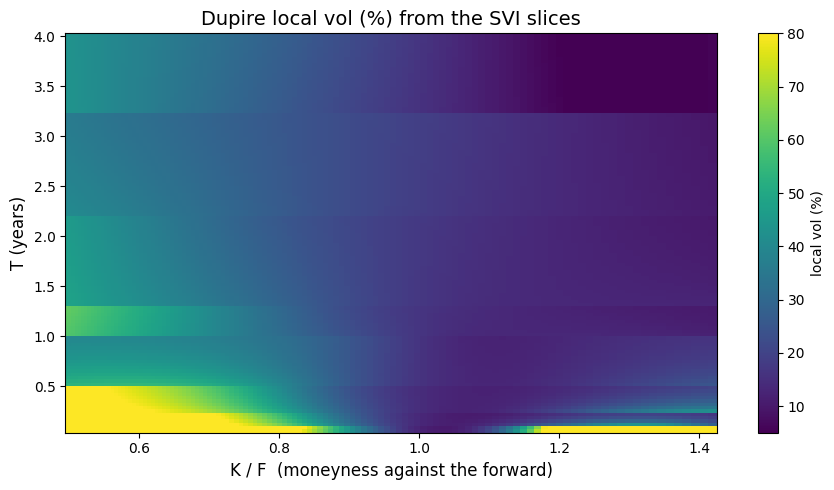

In [9]:
F = S0 * np.exp((cal.flat_r - cal.flat_q) * cal.flat_T); k_all = np.log(cal.flat_K / F)
surf_rows = {}
for name, surf in [('SSVI (global rho, power-law phi)', SSVISurface(sorted(df_all['T'].unique()))), ('SVI slices (5 params per expiry)', SVISurface(sorted(df_all['T'].unique())))]:
    t0 = time.perf_counter(); surf.fit(k_all, cal.flat_T, cal.market_iv, weights=cal.quote_weights * len(cal.quote_weights)); secs = time.perf_counter() - t0
    res = 100 * (surf.iv(k_all, cal.flat_T) - cal.market_iv)
    by_T = pd.Series(res**2).groupby(cal.flat_T).mean().pow(0.5)
    surf_rows[name] = {'fit RMSE (vol pts)': 100 * surf.fit_rmse, 'max |err|': np.abs(res).max(), 'seconds': secs, **{f"{t:.2f}y": v for t, v in by_T.items()}}
    if 'SVI slices' in name: SURF = surf
    else: SSVI = surf
display(pd.DataFrame(surf_rows).T.round(3))
kg = np.linspace(-1.5, 0.8, 200); Wp = np.array([svi_w(kg, *p) for p in SURF.params])
print("SVI slices: min butterfly g(k) per slice:", [round(float(svi_g(kg, *p).min()), 4) for p in SURF.params])
print("            min calendar gap w(T_{i+1}) - w(T_i):", np.round(np.diff(Wp, axis=0).min(axis=1), 6))
print("SSVI: eta(1+|rho|) =", round(SSVI.eta * (1 + abs(SSVI.rho)), 3), "(butterfly-free if <= 2); theta increasing:", bool(np.all(np.diff(SSVI.thetas) > 0)))

# Dupire local vol heat map from the SVI slices
kk = np.linspace(-0.7, 0.35, 120); tt = np.linspace(0.05, T_MAX, 120)
KK, TT = np.meshgrid(kk, tt); LV = np.sqrt(SURF.local_var(KK.ravel(), TT.ravel())).reshape(KK.shape).clip(0.03, 1.5)
fig, ax = plt.subplots(figsize=(9, 5)); im = ax.pcolormesh(np.exp(kk), tt, 100 * LV, shading='auto', cmap='viridis', vmin=5, vmax=80)
ax.set_xlabel('K / F  (moneyness against the forward)', fontsize=12); ax.set_ylabel('T (years)', fontsize=12); ax.set_title('Dupire local vol (%) from the SVI slices', fontsize=14)
plt.colorbar(im, ax=ax, label='local vol (%)'); plt.tight_layout(); plt.show()


## 8. LV, Heston and LSV for the note
Three dynamics, same random numbers (50,000 paths, daily, seed 42), same payoff code:
- **Local vol** (Dupire): $dS/S=(r-q)dt+\sigma_{\text{loc}}(S,t)\,dW$. Reprices every vanilla by construction; forward skews flatten.
- **Heston** (the 6M+ fit): misses the short end, keeps a forward skew.
- **LSV**: $dS/S=(r-q)dt+L(S,t)\sqrt{V_t}\,dW$ with Heston's $V$ and $L^2(S,t)=\sigma^2_{\text{loc}}(S,t)/E[V_t\,|\,S_t=S]$ (Gyöngy). The conditional expectation is estimated on the fly from the simulated paths (particle method of Guyon and Henry-Labordère 2011; here a local-linear regression of $V$ on $\log S$ inside quantile bins). The variance uses the QE step, the spot a log-Euler step correlated through $\rho$.

The vanilla check prices the out-of-the-money option on the paths and inverts it, at 60% to 110% strikes on each expiry, and compares with the SVI surface the LV/LSV were built from (Heston is compared with the same surface). A flat-local-vol test (not shown; in the development log) reproduces Black-Scholes within Monte Carlo noise under LSV.


In [10]:
def vanilla_check(pricer, label):
    rows = []
    for b in cal.data_batches:
        if b['T'] > T_MAX: continue
        Ks = np.array([0.6, 0.7, 0.8, 0.9, 1.0, 1.1]) * S0
        iv, se = mc_vanilla_iv(pricer, b['T'], Ks, rate_curve_func, dividend_curve_func, S0)
        tg = pricer.time_grid[pricer._get_time_index(b['T'])]; rT = cal.r_curve(tg); qT = dividend_curve_func(tg); Fm = S0 * np.exp((rT - qT) * tg)
        iv_s = SURF.iv(np.log(Ks / Fm), tg)
        for K_, a_, s_ in zip(Ks, iv, iv_s): rows.append({'T': f"{b['T']:.2f}y", 'K/S0': f"{K_/S0:.0%}", 'MC - surface (vol pts)': 100 * (a_ - s_)})
    d = pd.DataFrame(rows).pivot(index='T', columns='K/S0', values='MC - surface (vol pts)')
    print(f"{label}: Monte Carlo implied vol minus SVI surface, vol points (RMS over the table {np.sqrt(np.mean(d.values**2)):.2f})"); display(d.round(2))

price_rows = []; pricers = {}
for label, pricer in [('Local vol (Dupire)', LocalVolPricer(S0, S0, rate_curve_func, dividend_curve_func, PARAMS, SURF, use_sv=False)),
                      ('Heston (6M+ fit)', HestonAutocallPricer(S0, S0, rate_curve_func, dividend_curve_func, PARAMS, scheme='qe')),
                      ('LSV (Heston + leverage)', LocalVolPricer(S0, S0, rate_curve_func, dividend_curve_func, PARAMS, SURF, use_sv=True))]:
    t0 = time.perf_counter(); pricer.run_simulation(T_MAX, 252, 50000, obs_times=OBS_TIMES, seed=42, verbose=False); secs = time.perf_counter() - t0
    px = pricer.price_structure(**PRODUCT_PARAMS, pricing_date=PRICING_DATE, verbose=False); oc = pricer.outcomes
    mart = pricer.martingale_check([1.0, T_MAX])
    price_rows.append({'dynamics': label, 'price': px[0], 's.e.': pricer.std_error, 'principal': px[1], 'coupons': px[2], 'put': px[3], 'P(call 1Y)': oc['call_prob_by_date'][0],
                       'P(KI)': oc['prob_knock_in'], 'E[level | KI]': oc['mean_perf_given_ki'], 'life (y)': oc['expected_life'],
                       'fair coupon @ par': pricer.solve_fair_coupon(PRODUCT_PARAMS, 1000.0, pricing_date=PRICING_DATE), 'martingale dev 4Y (s.e.)': f"{mart.iloc[1,1]:+.4f} ({mart.iloc[1,2]:.4f})", 'sim s': secs})
    pricers[label] = pricer
    vanilla_check(pricer, label)
dyn_table = pd.DataFrame(price_rows).set_index('dynamics')
display(dyn_table.round(4))
print("LSV leverage L at the last step, 5/50/95% quantiles:", np.round(np.percentile(pricers['LSV (Heston + leverage)'].leverage_last, [5, 50, 95]), 3))


Local vol (Dupire): Monte Carlo implied vol minus SVI surface, vol points (RMS over the table 0.37)


K/S0,100%,110%,60%,70%,80%,90%
T,,,,,,
0.09y,0.02,-0.42,-1.33,-1.31,-1.06,-0.54
0.25y,0.17,-0.05,0.35,0.30,0.19,0.19
0.50y,0.10,-0.13,0.12,0.06,0.04,0.05
1.00y,0.13,-0.09,-0.07,-0.02,0.03,0.09
1.31y,0.26,-0.24,0.00,0.11,0.17,0.20
2.21y,0.13,0.16,0.11,0.16,0.17,0.13
3.22y,0.02,0.04,0.08,0.06,0.05,0.02


Heston (6M+ fit): Monte Carlo implied vol minus SVI surface, vol points (RMS over the table 2.17)


K/S0,100%,110%,60%,70%,80%,90%
T,,,,,,
0.09y,0.57,2.06,-10.62,-7.38,-2.35,1.43
0.25y,-0.28,1.10,-2.84,-0.97,0.61,1.29
0.50y,-0.23,-0.52,-1.21,-0.24,0.50,0.74
1.00y,-0.37,-0.63,1.32,0.76,0.24,-0.12
1.31y,-0.06,-0.61,0.07,0.01,0.06,0.07
2.21y,0.29,0.23,-0.15,0.03,0.19,0.29
3.22y,0.29,0.36,0.01,0.08,0.14,0.21


LSV (Heston + leverage): Monte Carlo implied vol minus SVI surface, vol points (RMS over the table 0.53)


K/S0,100%,110%,60%,70%,80%,90%
T,,,,,,
0.09y,-0.30,1.37,-2.59,-1.14,-0.65,-0.31
0.25y,-0.21,0.56,0.51,0.37,0.25,0.12
0.50y,-0.09,0.07,0.08,0.11,0.03,-0.02
1.00y,0.09,0.01,0.26,0.18,0.10,0.05
1.31y,0.17,-0.11,0.00,0.04,0.08,0.13
2.21y,0.12,0.14,0.03,0.03,0.05,0.10
3.22y,0.17,0.20,0.10,0.11,0.14,0.16


,price,s.e.,principal,coupons,put,P(call 1Y),P(KI),E[level | KI],life (y),fair coupon @ par,martingale dev 4Y (s.e.),sim s
dynamics,,,,,,,,,,,,
Local vol (Dupire),960.1127,0.8562,929.2864,68.1729,-37.3466,0.6865,0.0674,0.3228,1.5593,0.0476,-0.0005 (0.0016),4.9810
Heston (6M+ fit),975.3993,0.6959,928.6933,71.6175,-24.9115,0.7001,0.0491,0.3800,1.5734,0.0403,-0.0018 (0.0017),5.2582
LSV (Heston + leverage),972.8370,0.7260,927.4366,72.4384,-27.0380,0.6854,0.0523,0.3680,1.6002,0.0412,-0.0016 (0.0016),13.1769


LSV leverage L at the last step, 5/50/95% quantiles: [0.125 0.83  1.614]


## 9. Conclusions

**1. Vanilla engine.** The current Lewis FFT with a cubic spline has a worst error of 0.42 index points (0.05 vol points) at 1M and costs 9 ms per surface. Carr-Madan with $\alpha=1.5$ is a hundred times more accurate (0.003 points, 0.003 vol points) at 11 ms, and COS with 256 terms is as accurate in vol terms at 15 ms. Both are drop-in replacements; the engine error is already ten times below the quote floor, so this changes nothing in the calibration results but is the right choice going forward. Two cautions the table makes visible: the Carr-Madan damping matters ($\alpha=0.75$ breaks down in the wings), and Heston's original two-integral form is both slow (3 s) and wrong deep out of the money at 1M (46 vol points) because its $1/u$ integrands converge so slowly.

**2. Implied vol.** Bisection with 30 iterations is exact to $2\times10^{-7}$ vol points at 4 ms for 1,273 options, half the cost of the 50-iteration version and 300 times faster than Brent per option. Newton needs 25 safeguarded iterations to be reliable and is then no faster.

**3. Objective.** The current spread-weighted vol RMSE gives the best surface fit (0.90 vol points overall, 0.61 on 6M+) and the vega-weighted price objective is the closest alternative (0.99 / 0.61) with the best price RMSE among the vol-space choices. The v1 price objective fits prices 20% better (10.0 vs 12.2 points) at the cost of a vol RMSE of 1.6 and an 18.6-vol miss. Relative price error is the one to avoid: it hands the deep OTM quotes the whole objective and ruins the long end (2.2 vol points on 6M+, 27 index points). Huber does not help: the misfit is systematic in the wings, not a few outliers.

**4. Optimiser.** The 5-parameter Heston problem is benign from a sensible start. `least_squares` on the residual vector reaches the same optimum (0.7729 vol points) as DE + L-BFGS-B in 8 function evaluations (about 50 with the finite-difference Jacobians) and 0.9 s, against 3,900 evaluations and 65 s; Nelder-Mead, SHGO, basin hopping, a small-population DE and multistart L-BFGS-B all reach the same point. DE with the rand1bin strategy and dual annealing at the budget given do not. For the 10-parameter double Heston, eight Latin-hypercube `least_squares` starts reach 0.3620 in 102 s where DE gave 0.408 or 0.364 depending on the seed in 230-250 s, and a `least_squares` polish of the DE result gets there in 5 s. Two different parameter sets share that objective (vol-of-vol of the first factor 0.39 vs 3.8), so the two-factor model is not identified by this surface. Recommendation: Levenberg-Marquardt / trust-region least squares from a heuristic start, with a handful of random restarts for larger models, and keep DE as a check rather than the default.

**5. Expiry selection.** Taking the most liquid listed expiry within ±15% of each target instead of the nearest one adds 44% more quotes, improves the 6M+ fit from 0.615 to 0.571 vol points and the product-strike error from 0.156 to 0.147, with parameters that barely move. It also moves the "1M" pillar to the 7-week monthly expiry. A modest gain worth taking.

**6. Monte Carlo.** Control variates built from the note's own building blocks (the 1Y ATM digital, the 4Y 60% put, the 4Y 70% and 60% digitals, all priced by the FFT) double the efficiency; antithetic variates add another 15%, and the two together give 2.3x. Scrambled Sobol does not pay for this payoff: at 2,034 dimensions with digitals at fixed dates, it matches pseudo-random at best and the Brownian bridge makes it worse, because the bridge helps smooth payoffs that depend on the whole path and this one depends on the index at seven dates and on the variance path. Euler at daily steps is as good as QE at 25% less cost per path; QE's advantage is at coarser steps, shown in `main.ipynb`.

**7. Surfaces.** SSVI with one correlation for the whole surface cannot fit this snapshot (1.27 vol points RMSE, both no-arbitrage constraints binding). Slice-by-slice SVI fits at 0.25 vol points with the butterfly function $g(k)\ge0$ on every slice and a calendar gap no worse than $6\times10^{-5}$ in total variance. The 4.2Y slice remains the weak point (0.75 vol points) for the same reason as everywhere else: its quotes are four vol points wide.

**8. What the dynamics do to the note.** Same random numbers, same payoff, three dynamics:

| | Local vol | LSV | Heston |
|---|---|---|---|
| Price | 960.1 | 972.8 | 975.4 |
| Knock-in put (client short) | −37.3 | −27.0 | −24.9 |
| P(knock-in) | 6.7% | 5.2% | 4.9% |
| Mean level given knock-in | 32% | 37% | 38% |
| Fair coupon at par | 4.76% | 4.12% | 4.03% |

Local vol and LSV reprice the same vanillas (RMS 0.37 and 0.53 vol points against the surface, the residual being the 1M wings), so the 12.7 per 1,000 between them is pure dynamics: forward skew and the behaviour of volatility in a sell-off. Under local vol the volatility at 60-70% of spot is a fixed 40-50%, so a path that gets there keeps falling; under Heston the variance there is stochastic and mean-reverts to 23%. That is the model risk on this note, 1.3% of notional or 15 standard errors, and it is the number a reserve should be sized on. The 2.6 between LSV and Heston is what fitting every vanilla exactly is worth once the dynamics are Heston's. LSV is the model to price this note with: it is the only one of the three that both reprices the vanillas and has a forward skew. The leverage function runs from 0.1 to 1.6 across the state space at 4 years, which says the 6M+ Heston fit is a rough approximation of the surface's dynamics rather than a near-exact one.

**What to change in `main.ipynb` on the strength of this:** Carr-Madan or COS for the engine, 30 bisection iterations, `least_squares` from the heuristic start with DE kept as a check, the liquid-expiry rule, control variates in the pricer, and LSV as the pricing model with Heston as the benchmark.
